# E19 - the relevance map on a real report with distinct subjects

**Author**: Konrad Jelen (kj)<br>
**Date**: 2026-10-12<br>
**Pipeline stage**: experiment - registered batch `E19`, notebook B, hypotheses `E19-H93`, `E19-H94`, `E19-H96`, `E19-H97`<br>
**Execution model**: session model (one executor agent for the notebook, one independent verifier)

**Purpose** - measure whether the plain nearest ground cost ranks the statements of the target section of a briefing note on a real report whose sections cover distinct subjects (`E19-H93`), and whether the anisotropy pre-pass (`E19-H94`), the background contrast over the other notes (`E19-H96`) and an exact Otsu split of that contrast (`E19-H97`) add to it. The fixture is the Annex 1 of the European Commission report "State of the Digital Decade 2024" (883 statements) against 14 notes of the European Parliamentary Research Service, 13 with target sections and 1 without.

**Terms used below**

- **baseline** - `b_i = min_j c_ij`, the nearest ground cost of report statement `i` over the note statements `j`, with `c = cost_matrix(E_report, E_note)`; lower means more relevant
- **contrast** (`E19-H96`) - `s_i(n) = b_i(n)` minus the mean of `b_i` over the other 12 notes with a target section; lower means more relevant
- **pre-pass** (`E19-H94`) - `all_but_the_top` with `k = 1` over the pooled statements of report and note, then `min_j c'_ij`
- **AUC** - the probability that a random positive statement has a higher relevance score than a random negative one, ties count one half; the relevance score is the negative of the cost-type score
- **positive / negative / neutral** - for a note, the statements under its target headings / all other scored statements / the statements under the introduction, chapter 1, or a related heading of the note; neutral statements are left out of every metric
- **unit** - a heading of `sections.json` with role `chapter`, `numbered` or `subheading`; a statement belongs to the deepest unit of its path
- **top-3 hit** - one of the 3 best-ranked units is a target heading or lies below one
- **Otsu split** - the threshold that maximises the between-class variance of a score; a statement is marked match when its score is at or below it

Nothing under `src/`, `tests/`, `docs/` or the fixture is edited. Every bar is the registered one and is applied as written.

## Cells copied from the template

The notebooks `E18-kj-contrast-replication.ipynb` and `E18-kj-reranker-relevance.ipynb` are the template. Copied without a change of logic: the environment cell, the import cell, the single `DocDistance()` with the default reader and `embed_statements`, the reading of the `section` field of the `flows` of `semantic_distance_with_details`, `auc` (Mann-Whitney, ties one half), the bootstrap (10000 resamples, seed 0), `balanced_accuracy`, `otsu_threshold` (exact split), the `contrast_score` form and the `section_reading` idea. New for this fixture: the labels (`labels.json`, field `rule`), the section units from `sections.json`, the pre-pass score and the hard-negative AUC.

## Environment

In [1]:
import os
import warnings

os.environ["CUDA_VISIBLE_DEVICES"] = ""            # no GPU: the shipped OpenVINO INT8 CPU path is the path under test
os.environ["CUDA_DEVICE_ORDER"] = "PCI_BUS_ID"
os.environ["HF_HUB_OFFLINE"] = "1"                 # models resolve from the local cache through docdistance.json
os.environ["CI"] = "true"                          # disables OpenVINO telemetry
os.environ["TOKENIZERS_PARALLELISM"] = "false"
os.environ["TRANSFORMERS_VERBOSITY"] = "error"
os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"
os.environ["DOCDISTANCE_HOME"] = "/home/lab/workspace/learning/projects/docdistance"   # docdistance.json lives at the repo root

warnings.filterwarnings("ignore")
print("environment set: CPU only, models offline, DOCDISTANCE_HOME pinned")

environment set: CPU only, models offline, DOCDISTANCE_HOME pinned


## Imports

In [2]:
# Standard library
import contextlib                      # silence the model-load stderr output
import hashlib                         # sha256 of the fixture files
import io                              # sink for the redirected stderr
import json                            # labels, registration and metrics JSON
import platform                        # python version
import re                              # split a heading into number and title
import time                            # wall time
from datetime import datetime, timezone
from pathlib import Path               # fixture paths

# Scientific
import numpy as np                     # arrays
import ot                              # POT version line
from scipy.stats import rankdata       # average ranks for the Mann-Whitney AUC

# Visualisation
import matplotlib.pyplot as plt        # inline figures, object-oriented API

# Console
from rich.console import Console
from rich.markup import escape
from rich.table import Table

# The shipped package under test - imported, never edited
import docdistance
from docdistance.distance import all_but_the_top, cost_matrix        # anisotropy pre-pass; ground cost sqrt(2 - 2cos)
from docdistance.pipeline import DIFF_CHANGED_COST, DocDistance      # shipped reader, segmenter, encoder; fixed cutoff

%matplotlib inline
console = Console(width=220, highlight=False)
T_START = time.time()
print(f"docdistance {docdistance.__version__} | POT {ot.__version__} | numpy {np.__version__} | python {platform.python_version()}")

docdistance 1.1.32 | POT 0.9.6.post1 | numpy 2.4.6 | python 3.14.8


## Configuration

In [3]:
SEED = 0
ROOT = Path(os.environ["DOCDISTANCE_HOME"])
FIXTURE = ROOT / "data/processed/relevance-fixture-eu"
REGISTRATION = ROOT / "reports/E19-relevance/E19-relevance-registration.json"
METRICS_FILE = ROOT / "reports/E19-real-document-map-metrics.json"
COSTS_FILE = ROOT / "data/interim/E19/baseline-costs.npz"

BATCH_GATE_AUC = 0.95                  # baseline mean AUC at or above this kills E19-H94 and E19-H96 at the gate
H93_BAR_AUC = 0.80                     # baseline mean AUC bar of E19-H93
H93_BAR_HITS = 10                      # notes (of 13) with a top-3 hit
BAR_GAIN = 0.03                        # mean AUC difference to the baseline (E19-H94, E19-H96)
BAR_COUNT = 10                         # notes (of 13) with a difference above 0
H97_GATE_BA = 0.65                     # fixed-cutoff mean balanced accuracy at or above this kills E19-H97
H97_BAR_BA = 0.70                      # Otsu mean balanced accuracy must reach this
H97_BAR_GAIN = 0.10                    # and exceed the fixed cutoff's by this
N_BOOT = 10000                         # bootstrap resamples of the mean difference
MIN_TARGET = 5                         # statements a note's targets hold in total
MIN_UNIT = 5                           # statements a unit holds to be ranked
TOP_UNITS = 3                          # section-reading top rank
UNIT_ROLES = ("chapter", "numbered", "subheading")
SEP = " > "

LABELS = json.loads((FIXTURE / "labels.json").read_text(encoding="utf-8"))
SECTIONS = json.loads((FIXTURE / "sections.json").read_text(encoding="utf-8"))
REG = json.loads(REGISTRATION.read_text(encoding="utf-8"))
NEUTRAL = LABELS["neutral_sections"]
NOTES = LABELS["notes"]
NO_TARGET = LABELS["no_target_notes"]
assert len(NO_TARGET) == 1
NO_TARGET_ID = next(iter(NO_TARGET))
NOTE_IDS = sorted(NOTES)
ALL_NOTE_IDS = sorted(NOTE_IDS + [NO_TARGET_ID])
assert len(NOTE_IDS) == 13 and NO_TARGET_ID not in NOTE_IDS
NOTE_FILE = {**{n: NOTES[n]["file"] for n in NOTE_IDS}, NO_TARGET_ID: NO_TARGET[NO_TARGET_ID]["file"]}

table = Table(title="Configuration", show_lines=False)
table.add_column("item"); table.add_column("value")
for key, value in [
    ("fixture", FIXTURE.relative_to(ROOT)), ("notes with target / without", f"{len(NOTE_IDS)} / {NO_TARGET_ID}"),
    ("neutral sections", NEUTRAL), ("DIFF_CHANGED_COST (fixed cutoff)", DIFF_CHANGED_COST),
    ("gate H94, H96", f"baseline mean AUC over 13 notes >= {BATCH_GATE_AUC} kills at the gate"),
    ("gate H97", f"fixed-cutoff mean balanced accuracy >= {H97_GATE_BA} kills at the gate"),
    ("bar H93", f"baseline mean AUC >= {H93_BAR_AUC} and top-3 hit for >= {H93_BAR_HITS} of 13"),
    ("bar H94, H96", f"mean AUC difference >= {BAR_GAIN} and difference > 0 in >= {BAR_COUNT} of 13"),
    ("bar H97", f"Otsu mean balanced accuracy >= {H97_BAR_BA} and >= {H97_BAR_GAIN} above the fixed cutoff's"),
    ("section reading", f"units {UNIT_ROLES}, units with < {MIN_UNIT} statements left out, top {TOP_UNITS}"),
    ("bootstrap", f"{N_BOOT} resamples of the 13 notes, seed {SEED}"),
]:
    table.add_row(str(key), str(value))
console.print(table)

                                                        Configuration                                                        
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ item                             ┃ value                                                                                  ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ fixture                          │ data/processed/relevance-fixture-eu                                                    │
│ notes with target / without      │ 13 / 760391-gdpr-cross-border-procedural-rules                                         │
│ neutral sections                 │ ['Introduction', '1. Key drivers of the EU’s digital transformation in 2024']          │
│ DIFF_CHANGED_COST (fixed cutoff) │ 0.3252691193458119                                                                     │
│ gate H94, H96                    │ baseline mean AUC over 13 notes >= 0.95 kills at the gate                              │
│ gate H97                         │ fixed-cutoff mean balanced accuracy >= 0.65 kills at the gate                          │
│ bar H93                          │ baseline mean AUC >= 0.8 and top-3 hit for >= 10 of 13                                 │
│ bar H94, H96                     │ mean AUC difference >= 0.03 and difference > 0 in >= 10 of 13                          │
│ bar H97                          │ Otsu mean balanced accuracy >= 0.7 and >= 0.1 above the fixed cutoff's                 │
│ section reading                  │ units ('chapter', 'numbered', 'subheading'), units with < 5 statements left out, top 3 │
│ bootstrap                        │ 10000 resamples of the 13 notes, seed 0                                                │
└──────────────────────────────────┴────────────────────────────────────────────────────────────────────────────────────────┘

## Fixture hash check and label counts

In [4]:
fixture_sha = {rel: hashlib.sha256((ROOT / rel).read_bytes()).hexdigest() for rel in REG["fixture_sha256"]}
HASH_EQUAL = fixture_sha == REG["fixture_sha256"]
assert HASH_EQUAL, "fixture differs from the registration"
print(f"fixture sha256: all {len(fixture_sha)} files equal the registration")

with contextlib.redirect_stderr(io.StringIO()):
    dd = DocDistance()
    report_path = FIXTURE / LABELS["report"]
    R_TEXTS, E_R = dd.embed_statements(report_path)
    first = NOTE_IDS[0]
    _, DETAIL = dd.semantic_distance_with_details(report_path, FIXTURE / NOTE_FILE[first])
    NOTE_TEXTS, E_NOTE = {}, {}
    for nid in ALL_NOTE_IDS:
        NOTE_TEXTS[nid], E_NOTE[nid] = dd.embed_statements(FIXTURE / NOTE_FILE[nid])

FLOWS = DETAIL["flows"]
assert [f["text"] for f in FLOWS] == R_TEXTS, "flow texts differ from the report statements"
SECTION_PATH = [f["section"] for f in FLOWS]
assert all(SECTION_PATH), "a report statement has no section"
N_REPORT = len(R_TEXTS)
assert N_REPORT == 883, f"the report holds {N_REPORT} statements, not 883"
ELEMENTS = [p.split(SEP) for p in SECTION_PATH]
CHAPTER = np.array([e[0] for e in ELEMENTS])
console.print(f"report {N_REPORT} statements in {len(set(SECTION_PATH))} distinct section paths; backend {dd.backend}")
console.print("note statements " + ", ".join(f"{n[:6]}: {len(NOTE_TEXTS[n])}" for n in ALL_NOTE_IDS))

distinct_elements = sorted({el for e in ELEMENTS for el in e})
console.print(escape(f"distinct path elements: {len(distinct_elements)}"))
declared = set(NEUTRAL) | {h for n in NOTES.values() for h in n["target_sections"] + n["related_sections"]}
missing = sorted(declared - set(distinct_elements))
console.print(escape("declared headings that match no path element: " + (str(missing) if missing else "none")))
assert not missing, "a declared heading matches no path element"
for el in distinct_elements:
    console.print(escape(el))

fixture sha256: all 18 files equal the registration


report 883 statements in 113 distinct section paths; backend openvino

note statements 739206: 51, 739350: 49, 747926: 32, 751386: 23, 754642: 29, 759583: 26, 759620: 29, 760355: 52, 760391: 22, 760392: 32, 760421: 25, 772906: 26, 779193: 56, 779252: 51

distinct path elements: 88

declared headings that match no path element: none

...

Take up of cloud services

Technological leadership - Recommended policies, measures and actions (49):

Unicorns - Recommended policies, measures and actions:

e-Government services - Recommended policies, measures and actions:

e-health - Recommended policies, measures and actions:

In [5]:
IS_NEUTRAL_ALL = np.array([any(el in NEUTRAL for el in e) for e in ELEMENTS])
LAB = {}
for nid in ALL_NOTE_IDS:
    targets = NOTES[nid]["target_sections"] if nid in NOTES else []
    related = NOTES[nid]["related_sections"] if nid in NOTES else []
    neutral = IS_NEUTRAL_ALL | np.array([any(el in related for el in e) for e in ELEMENTS])
    pos = np.array([any(el in targets for el in e) for e in ELEMENTS]) & ~neutral
    neg = ~pos & ~neutral
    LAB[nid] = {"pos": pos, "neg": neg, "neutral": neutral, "targets": targets, "related": related}
    if nid in NOTES:
        assert pos.sum() >= MIN_TARGET, f"{nid}: targets hold {int(pos.sum())} statements, fewer than {MIN_TARGET}"
    else:
        assert pos.sum() == 0
    assert pos.sum() + neg.sum() + neutral.sum() == N_REPORT
LABEL_ASSERTION_PASSED = True

table = Table(title="Label counts")
for col in ("note", "positives", "neutral", "negatives", "note statements", "target headings"):
    table.add_column(col, justify="left" if col in ("note", "target headings") else "right")
for nid, lab in LAB.items():
    table.add_row(nid, str(lab["pos"].sum()), str(lab["neutral"].sum()), str(lab["neg"].sum()), str(len(NOTE_TEXTS[nid])), escape("; ".join(lab["targets"]) or "none (no target section)"))
console.print(table)

                                                                                                    Label counts                                                                                                    
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━┳━━━━━━━━━┳━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ note                                      ┃ positives ┃ neutral ┃ negatives ┃ note statements ┃ target headings                                                                                                  ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━╇━━━━━━━━━╇━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ 739206-european-year-of-skills            │        67 │      68 │       748 │              51 │ 3.1.1. Equip people with digital skills                                                                          │
│ 739350-online-age-verification            │        25 │     122 │       736 │              49 │ 3.2.2. Protect and empower children (including via age verification)                                             │
│ 747926-ai-act-parliament-position         │        16 │      85 │       782 │              32 │ 3.2.3. Promote responsible and human-centric AI systems                                                          │
│ 751386-eu-chips-act                       │        38 │      68 │       777 │              23 │ 2.1.3.2 Semiconductors                                                                                           │
│ 754642-european-health-data-space         │        26 │      68 │       789 │              29 │ 3.1.4. Leverage on digital technologies for health                                                               │
│ 759583-strategic-technologies-platform    │        54 │      68 │       761 │              26 │ 2.1.1. Investing in research and innovation; 5.3. Synergising funding for digitalisation                         │
│ 759620-european-media-freedom-act         │        13 │      91 │       779 │              29 │ 3.3.2. Access to media and media pluralism                                                                       │
│ 760355-foreign-interference-preparedness  │        23 │     116 │       744 │              52 │ 3.3.1. Address disinformation and preserve election integrity                                                    │
│ 760391-gdpr-cross-border-procedural-rules │         0 │      68 │       815 │              22 │ none (no target section)                                                                                         │
│ 760392-ai-investment-indicators           │        17 │     137 │       729 │              32 │ Take up of artificial intelligence                                                                               │
│ 760421-gigabit-infrastructure-act         │        57 │      68 │       758 │              25 │ 2.1.3.1 Gigabit connectivity infrastructure                                                                      │
│ 772906-ai-act-implementation-timeline     │        16 │      85 │       782 │              26 │ 3.2.3. Promote responsible and human-centric AI systems                                                          │
│ 779193-simplifying-digital-laws           │        19 │      94 │       770 │              56 │ 5.2. Striving for an effective, efficient and red-tape free implementation of the digital regulatory environment │
│ 779252-cybersecurity-act-review           │        35 │      68 │       780 │              51 │ 2.3. Strengthening cybersecurity                                                                                 │
└───────────────────────────────────────────┴───────────┴─────────┴───────────┴─────────────────┴─────────────────────────────────────────────────────────────────────

## Scores

In [6]:
BASE_COST = {nid: cost_matrix(E_R, E_NOTE[nid]).astype(np.float64).min(axis=1) for nid in ALL_NOTE_IDS}
PRE_COST = {}
for nid in ALL_NOTE_IDS:
    pooled = all_but_the_top({"a": E_R, "b": E_NOTE[nid]}, k=1)
    PRE_COST[nid] = cost_matrix(pooled["a"], pooled["b"]).astype(np.float64).min(axis=1)
BACKGROUND = {nid: [b for b in NOTE_IDS if b != nid] for nid in ALL_NOTE_IDS}
assert all(len(v) == 12 for nid, v in BACKGROUND.items() if nid in NOTE_IDS) and len(BACKGROUND[NO_TARGET_ID]) == 13
CONTRAST_COST = {nid: BASE_COST[nid] - np.mean([BASE_COST[b] for b in BACKGROUND[nid]], axis=0) for nid in ALL_NOTE_IDS}
COSTS_FILE.parent.mkdir(parents=True, exist_ok=True)
np.savez(COSTS_FILE, **{n: BASE_COST[n] for n in ALL_NOTE_IDS})
print(f"baseline nearest costs of {len(ALL_NOTE_IDS)} notes stored in {COSTS_FILE.relative_to(ROOT)}")

SCORE_COST = {"baseline": BASE_COST, "H94": PRE_COST, "H96": CONTRAST_COST}
SCORES = list(SCORE_COST)
REL = {s: {n: -SCORE_COST[s][n] for n in ALL_NOTE_IDS} for s in SCORES}          # relevance score: higher means more relevant


def auc(score, pos, neg):
    "Mann-Whitney AUC of a relevance score for positives against negatives; ties count one half"
    ranks = rankdata(np.concatenate([score[pos], score[neg]]))
    n_pos, n_neg = int(pos.sum()), int(neg.sum())
    return float((ranks[:n_pos].sum() - n_pos * (n_pos + 1) / 2) / (n_pos * n_neg))


def hard_negatives(nid):
    "Negatives of the chapter of the note's first target"
    first_target_row = int(np.flatnonzero(LAB[nid]["pos"])[0])
    return LAB[nid]["neg"] & (CHAPTER == CHAPTER[first_target_row])


def otsu_threshold(values):
    "Exact Otsu split of a sample: the midpoint between neighbouring distinct sorted values with the largest between-class variance"
    v = np.sort(values)
    distinct = np.unique(v)
    best_var, best_t = -1.0, None
    for t in (distinct[:-1] + distinct[1:]) / 2:
        lo, hi = v[v <= t], v[v > t]
        var = (len(lo) / len(v)) * (len(hi) / len(v)) * (lo.mean() - hi.mean()) ** 2
        if var > best_var:                       # strict: an exact tie keeps the lower threshold
            best_var, best_t = var, float(t)
    return best_t


def balanced_accuracy(match, pos, neg):
    "Mean of the recall on positives (match) and the recall on negatives (no match)"
    return float((match[pos].mean() + (~match[neg]).mean()) / 2)


AUC = {s: {n: auc(REL[s][n], LAB[n]["pos"], LAB[n]["neg"]) for n in NOTE_IDS} for s in SCORES}
AUC_HARD = {s: {n: auc(REL[s][n], LAB[n]["pos"], hard_negatives(n)) for n in NOTE_IDS} for s in SCORES}
HARD_NEG_COUNT = {n: int(hard_negatives(n).sum()) for n in NOTE_IDS}
print("scores computed: " + ", ".join(SCORES))

baseline nearest costs of 14 notes stored in data/interim/E19/baseline-costs.npz
scores computed: baseline, H94, H96


## Section reading

In [7]:
SECTION_ROWS = {(s["number"], s["title"]): s for s in SECTIONS["sections"] if s["role"] in UNIT_ROLES}
HEADING = re.compile(r"^(\d+(?:\.\d+)*)\.?\s+(.*)$")


def unit_key(element):
    "(number, title) of a path element; an unnumbered heading has number None"
    m = HEADING.match(element)
    return (m.group(1), m.group(2)) if m and (m.group(1), m.group(2)) in SECTION_ROWS else (None, element)


UNIT_OF = []                                   # per statement: the path prefix that ends at its deepest unit
for e in ELEMENTS:
    deepest = max((k for k in range(len(e)) if unit_key(e[k]) in SECTION_ROWS), default=None)
    assert deepest is not None, f"no unit in path {e}"
    UNIT_OF.append(SEP.join(e[: deepest + 1]))
UNIT_OF = np.array(UNIT_OF)
UNITS = list(dict.fromkeys(UNIT_OF))
UNIT_SIZE = {u: int((UNIT_OF == u).sum()) for u in UNITS}
RANKED_UNITS = [u for u in UNITS if UNIT_SIZE[u] >= MIN_UNIT]
found = {unit_key(el) for u in UNITS for el in u.split(SEP)} & set(SECTION_ROWS)
console.print(f"units in sections.json: {len(SECTION_ROWS)}; units reached by a statement path: {len(found)}; units that own a statement: {len(UNITS)}; with at least {MIN_UNIT}: {len(RANKED_UNITS)}")


def unit_is_target(u, nid):
    return any(el in LAB[nid]["targets"] for el in u.split(SEP))


def unit_is_neutral(u, nid):
    return any(el in NEUTRAL or el in LAB[nid]["related"] for el in u.split(SEP))


def section_reading(rel, nid):
    "Units (neutral and small ones left out) ranked from most to least relevant by mean score; rank of the best target unit"
    units = [u for u in RANKED_UNITS if not unit_is_neutral(u, nid)]
    means = np.array([float(rel[UNIT_OF == u].mean()) for u in units])
    ranked = [units[i] for i in np.argsort(-means, kind="stable")]
    ranks = [k + 1 for k, u in enumerate(ranked) if unit_is_target(u, nid)]
    return ranked, (min(ranks) if ranks else None)


READING = {s: {} for s in SCORES}
for s in SCORES:
    for n in NOTE_IDS:
        ranked, best = section_reading(REL[s][n], n)
        assert best is not None, f"{n}: no ranked target unit"
        READING[s][n] = {"best_target_rank": best, "top3": [u.split(SEP)[-1] for u in ranked[:TOP_UNITS]], "hit": bool(best <= TOP_UNITS), "n_ranked_units": len(ranked)}
HITS = {s: sum(READING[s][n]["hit"] for n in NOTE_IDS) for s in SCORES}
print("top-3 hits of 13 notes: " + ", ".join(f"{s} {HITS[s]}" for s in SCORES))

units in sections.json: 49; units reached by a statement path: 49; units that own a statement: 49; with at least 5: 41

top-3 hits of 13 notes: baseline 5, H94 12, H96 12


## Gates

In [8]:
def summary(name):
    "Mean AUC, mean difference to the baseline and notes with a difference above 0"
    diff = np.array([AUC[name][n] - AUC["baseline"][n] for n in NOTE_IDS])
    return {"mean_auc": float(np.mean([AUC[name][n] for n in NOTE_IDS])), "mean_diff": float(diff.mean()), "n_above_0": int((diff > 0).sum()), "n": len(NOTE_IDS)}


boot_rng = np.random.default_rng(SEED)
BOOT_IDX = boot_rng.integers(0, len(NOTE_IDS), size=(N_BOOT, len(NOTE_IDS)))     # one set of resamples shared by every score


def boot_ci(name):
    diff = np.array([AUC[name][n] - AUC["baseline"][n] for n in NOTE_IDS])
    boot = diff[BOOT_IDX].mean(axis=1)
    return float(np.percentile(boot, 2.5)), float(np.percentile(boot, 97.5))


SUMMARY = {s: summary(s) for s in SCORES}
for s in SCORES:
    SUMMARY[s]["boot_lo"], SUMMARY[s]["boot_hi"] = boot_ci(s)
    SUMMARY[s]["mean_auc_hard"] = float(np.mean([AUC_HARD[s][n] for n in NOTE_IDS]))
    SUMMARY[s]["mean_diff_hard"] = float(np.mean([AUC_HARD[s][n] - AUC_HARD["baseline"][n] for n in NOTE_IDS]))
    SUMMARY[s]["top3_hits"] = HITS[s]

BASE_MEAN = SUMMARY["baseline"]["mean_auc"]
GATE_AUC_KILLED = bool(BASE_MEAN >= BATCH_GATE_AUC)

BA = {}
for n in NOTE_IDS:
    lab = LAB[n]
    fixed_match = BASE_COST[n] <= DIFF_CHANGED_COST
    t = otsu_threshold(CONTRAST_COST[n])
    otsu_match = CONTRAST_COST[n] <= t
    BA[n] = {"fixed_ba": balanced_accuracy(fixed_match, lab["pos"], lab["neg"]), "otsu_ba": balanced_accuracy(otsu_match, lab["pos"], lab["neg"]), "otsu_threshold": t,
             "n_match_fixed": int(fixed_match.sum()), "n_match_otsu": int(otsu_match.sum()),
             "fixed_tpr": float(fixed_match[lab["pos"]].mean()), "fixed_tnr": float((~fixed_match[lab["neg"]]).mean()),
             "otsu_tpr": float(otsu_match[lab["pos"]].mean()), "otsu_tnr": float((~otsu_match[lab["neg"]]).mean())}
FIXED_MEAN = float(np.mean([BA[n]["fixed_ba"] for n in NOTE_IDS]))
OTSU_MEAN = float(np.mean([BA[n]["otsu_ba"] for n in NOTE_IDS]))
GATE_BA_KILLED = bool(FIXED_MEAN >= H97_GATE_BA)

console.print(f"gate 1 (E19-H94, E19-H96): baseline mean AUC over 13 notes {BASE_MEAN:.4f} vs {BATCH_GATE_AUC} -> {'KILLED at the gate (readings stored as beyond the gate)' if GATE_AUC_KILLED else 'passed (E19-H94 and E19-H96 go on to the bars)'}")
console.print(f"gate 2 (E19-H97): fixed cutoff {DIFF_CHANGED_COST:.4f} mean balanced accuracy over 13 notes {FIXED_MEAN:.4f} vs {H97_GATE_BA} -> {'KILLED at the gate (readings stored as beyond the gate)' if GATE_BA_KILLED else 'passed (E19-H97 goes on to the bar)'}")

gate 1 (E19-H94, E19-H96): baseline mean AUC over 13 notes 0.6374 vs 0.95 -> passed (E19-H94 and E19-H96 go on to the bars)

gate 2 (E19-H97): fixed cutoff 0.3253 mean balanced accuracy over 13 notes 0.5835 vs 0.65 -> passed (E19-H97 goes on to the bar)

## E19-H93 - the plain map

In [9]:
def verdict(killed, bar_met):
    return "Killed-at-gate" if killed else ("Confirmed" if bar_met else "Refuted")


c93 = {"baseline_mean_auc_ge_0.80": {"value": BASE_MEAN, "met": bool(BASE_MEAN >= H93_BAR_AUC)},
       "top3_hits_ge_10_of_13": {"value": HITS["baseline"], "met": bool(HITS["baseline"] >= H93_BAR_HITS)}}
c93["bar_met"] = bool(all(c["met"] for c in c93.values()))
DECISION = {"E19-H93": {"clauses": c93, "beyond_gate": False, "verdict_by_bar": verdict(False, c93["bar_met"])}}

table = Table(title="E19-H93 - baseline over the 13 notes with a target section")
for col in ("quantity", "value", "bar", "met"):
    table.add_column(col, justify="left" if col == "quantity" else "right")
table.add_row("mean AUC", f"{BASE_MEAN:.4f}", f">= {H93_BAR_AUC}", str(c93["baseline_mean_auc_ge_0.80"]["met"]))
table.add_row("top-3 hits", f"{HITS['baseline']}/13", f">= {H93_BAR_HITS}", str(c93["top3_hits_ge_10_of_13"]["met"]))
table.add_row("mean AUC with hard negatives (reported)", f"{SUMMARY['baseline']['mean_auc_hard']:.4f}", "-", "-")
table.add_row("notes with AUC >= 0.80 (reported)", f"{sum(AUC['baseline'][n] >= 0.80 for n in NOTE_IDS)}/13", "-", "-")
console.print(table)
console.print(f"E19-H93 verdict_by_bar: {DECISION['E19-H93']['verdict_by_bar']}")

     E19-H93 - baseline over the 13 notes with a target section      
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━━┳━━━━━━━┓
┃ quantity                                ┃  value ┃    bar ┃   met ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━╇━━━━━━━━╇━━━━━━━┩
│ mean AUC                                │ 0.6374 │ >= 0.8 │ False │
│ top-3 hits                              │   5/13 │  >= 10 │ False │
│ mean AUC with hard negatives (reported) │ 0.6305 │      - │     - │
│ notes with AUC >= 0.80 (reported)       │   0/13 │      - │     - │
└─────────────────────────────────────────┴────────┴────────┴───────┘

E19-H93 verdict_by_bar: Refuted

## E19-H94 and E19-H96 - pre-pass and contrast

In [10]:
def clauses_gain(name):
    s = SUMMARY[name]
    c = {"mean_diff_ge_0.03": {"value": s["mean_diff"], "met": bool(s["mean_diff"] >= BAR_GAIN)},
         "notes_above_0_ge_10": {"value": s["n_above_0"], "met": bool(s["n_above_0"] >= BAR_COUNT)}}
    c["bar_met"] = bool(all(v["met"] for v in c.values()))
    return c


for hid, name in (("E19-H94", "H94"), ("E19-H96", "H96")):
    c = clauses_gain(name)
    DECISION[hid] = {"clauses": c, "beyond_gate": GATE_AUC_KILLED, "verdict_by_bar": verdict(GATE_AUC_KILLED, c["bar_met"])}

table = Table(title="Score summary over the 13 notes - AUC of positives against negatives")
for col in ("score", "mean AUC", "mean diff", "notes > 0", "boot 95% (mean diff)", "mean AUC hard neg.", "mean diff hard neg.", "top-3 hits", "bar met", "verdict_by_bar"):
    table.add_column(col, justify="left" if col in ("score", "verdict_by_bar") else "right")
table.add_row("baseline", f"{SUMMARY['baseline']['mean_auc']:.4f}", "-", "-", "-", f"{SUMMARY['baseline']['mean_auc_hard']:.4f}", "-", f"{HITS['baseline']}/13", "-", DECISION["E19-H93"]["verdict_by_bar"] + " (H93)")
for hid, name in (("E19-H94", "H94"), ("E19-H96", "H96")):
    s = SUMMARY[name]
    table.add_row(f"{name} {'pre-pass' if name == 'H94' else 'contrast'}", f"{s['mean_auc']:.4f}", f"{s['mean_diff']:+.4f}", f"{s['n_above_0']}/13", f"[{s['boot_lo']:+.4f}, {s['boot_hi']:+.4f}]",
                  f"{s['mean_auc_hard']:.4f}", f"{s['mean_diff_hard']:+.4f}", f"{HITS[name]}/13", str(DECISION[hid]["clauses"]["bar_met"]),
                  DECISION[hid]["verdict_by_bar"] + (" (readings beyond the gate)" if GATE_AUC_KILLED else ""))
console.print(table)
for hid in ("E19-H94", "E19-H96"):
    c = DECISION[hid]["clauses"]
    console.print(f"{hid}: mean diff {c['mean_diff_ge_0.03']['value']:+.4f} >= {BAR_GAIN} -> {c['mean_diff_ge_0.03']['met']}; notes above 0: {c['notes_above_0_ge_10']['value']} >= {BAR_COUNT} -> {c['notes_above_0_ge_10']['met']}; verdict_by_bar {DECISION[hid]['verdict_by_bar']}")

                                            Score summary over the 13 notes - AUC of positives against negatives                                             
┏━━━━━━━━━━━━━━┳━━━━━━━━━━┳━━━━━━━━━━━┳━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━┳━━━━━━━━━━━━━━━━┓
┃ score        ┃ mean AUC ┃ mean diff ┃ notes > 0 ┃ boot 95% (mean diff) ┃ mean AUC hard neg. ┃ mean diff hard neg. ┃ top-3 hits ┃ bar met ┃ verdict_by_bar ┃
┡━━━━━━━━━━━━━━╇━━━━━━━━━━╇━━━━━━━━━━━╇━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━╇━━━━━━━━━━━━━━━━┩
│ baseline     │   0.6374 │         - │         - │                    - │             0.6305 │                   - │       5/13 │       - │ Refuted (H93)  │
│ H94 pre-pass │   0.7250 │   +0.0876 │     13/13 │   [+0.0603, +0.1170] │             0.7035 │             +0.0731 │      12/13 │    True │ Confirmed      │
│ H96 contrast │   0.7345 │   +0.0971 │     12/13 │   [+0.0427, +0.1405] │             0.7168 │             +0.0863 │      12/13 │    True │ Confirmed      │
└──────────────┴──────────┴───────────┴───────────┴──────────────────────┴────────────────────┴─────────────────────┴────────────┴─────────┴────────────────┘

E19-H94: mean diff +0.0876 >= 0.03 -> True; notes above 0: 13 >= 10 -> True; verdict_by_bar Confirmed

E19-H96: mean diff +0.0971 >= 0.03 -> True; notes above 0: 12 >= 10 -> True; verdict_by_bar Confirmed

## E19-H97 - Otsu split of the contrast

In [11]:
c97 = {"otsu_mean_ba_ge_0.70": {"value": OTSU_MEAN, "met": bool(OTSU_MEAN >= H97_BAR_BA)},
       "otsu_minus_fixed_ge_0.10": {"value": OTSU_MEAN - FIXED_MEAN, "met": bool(OTSU_MEAN - FIXED_MEAN >= H97_BAR_GAIN)}}
c97["bar_met"] = bool(all(v["met"] for v in c97.values()))
DECISION["E19-H97"] = {"gate": {"fixed_mean_ba": FIXED_MEAN, "threshold": H97_GATE_BA, "killed": GATE_BA_KILLED}, "clauses": c97, "otsu_mean_ba": OTSU_MEAN,
                       "beyond_gate": GATE_BA_KILLED, "verdict_by_bar": verdict(GATE_BA_KILLED, c97["bar_met"])}
cell = lambda d: f"[red]{d:+.4f}[/red]" if d < 0 else f"{d:+.4f}"
table = Table(title="E19-H97 per note - balanced accuracy of the fixed cutoff and of the Otsu split on the contrast")
for col in ("note", "fixed BA", "fixed match", "fixed TPR/TNR", "Otsu BA", "Otsu threshold", "Otsu match", "Otsu TPR/TNR", "Otsu - fixed"):
    table.add_column(col, justify="left" if col == "note" else "right")
for n in NOTE_IDS:
    h = BA[n]
    table.add_row(n, f"{h['fixed_ba']:.4f}", str(h["n_match_fixed"]), f"{h['fixed_tpr']:.2f}/{h['fixed_tnr']:.2f}", f"{h['otsu_ba']:.4f}", f"{h['otsu_threshold']:+.4f}",
                  str(h["n_match_otsu"]), f"{h['otsu_tpr']:.2f}/{h['otsu_tnr']:.2f}", cell(h["otsu_ba"] - h["fixed_ba"]))
table.add_row("mean", f"{FIXED_MEAN:.4f}", "", "", f"{OTSU_MEAN:.4f}", "", "", "", f"{OTSU_MEAN - FIXED_MEAN:+.4f}")
console.print(table)
console.print(f"E19-H97: gate fixed-cutoff mean BA {FIXED_MEAN:.4f} vs {H97_GATE_BA} -> {'KILLED' if GATE_BA_KILLED else 'passed'}; Otsu mean BA {OTSU_MEAN:.4f} >= {H97_BAR_BA} -> {c97['otsu_mean_ba_ge_0.70']['met']}; "
              f"Otsu minus fixed {OTSU_MEAN - FIXED_MEAN:+.4f} >= {H97_BAR_GAIN} -> {c97['otsu_minus_fixed_ge_0.10']['met']}; verdict_by_bar {DECISION['E19-H97']['verdict_by_bar']}{' (readings beyond the gate)' if GATE_BA_KILLED else ''}")

                              E19-H97 per note - balanced accuracy of the fixed cutoff and of the Otsu split on the contrast                               
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━┳━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┳━━━━━━━━━┳━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━┓
┃ note                                     ┃ fixed BA ┃ fixed match ┃ fixed TPR/TNR ┃ Otsu BA ┃ Otsu threshold ┃ Otsu match ┃ Otsu TPR/TNR ┃ Otsu - fixed ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━╇━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━╇━━━━━━━━━╇━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━┩
│ 739206-european-year-of-skills           │   0.6506 │          97 │     0.39/0.91 │  0.7138 │        -0.0180 │        368 │    0.81/0.62 │      +0.0632 │
│ 739350-online-age-verification           │   0.6640 │          74 │     0.40/0.93 │  0.7257 │        -0.0067 │        375 │    0.84/0.61 │      +0.0617 │
│ 747926-ai-act-parliament-position        │   0.5968 │         106 │     0.31/0.88 │  0.6742 │        -0.0047 │        424 │    0.81/0.54 │      +0.0774 │
│ 751386-eu-chips-act                      │   0.5288 │          41 │     0.11/0.95 │  0.6780 │        -0.0043 │        302 │    0.68/0.67 │      +0.1492 │
│ 754642-european-health-data-space        │   0.5361 │          39 │     0.12/0.96 │  0.5966 │        -0.0196 │        170 │    0.38/0.81 │      +0.0605 │
│ 759583-strategic-technologies-platform   │   0.5406 │          60 │     0.15/0.93 │  0.6209 │        -0.0081 │        342 │    0.61/0.63 │      +0.0804 │
│ 759620-european-media-freedom-act        │   0.6852 │          17 │     0.38/0.99 │  0.7735 │        +0.0131 │        362 │    0.92/0.62 │      +0.0882 │
│ 760355-foreign-interference-preparedness │   0.5968 │          68 │     0.26/0.93 │  0.6917 │        -0.0081 │        381 │    0.78/0.60 │      +0.0949 │
│ 760392-ai-investment-indicators          │   0.6012 │          34 │     0.24/0.97 │  0.7123 │        -0.0137 │        251 │    0.71/0.72 │      +0.1112 │
│ 760421-gigabit-infrastructure-act        │   0.5103 │          13 │     0.04/0.99 │  0.6372 │        +0.0061 │        335 │    0.65/0.63 │      +0.1269 │
│ 772906-ai-act-implementation-timeline    │   0.5249 │          12 │     0.06/0.99 │  0.6016 │        +0.0085 │        322 │    0.56/0.64 │      +0.0767 │
│ 779193-simplifying-digital-laws          │   0.5670 │          71 │     0.21/0.92 │  0.5180 │        -0.0070 │        491 │    0.58/0.46 │      -0.0489 │
│ 779252-cybersecurity-act-review          │   0.5837 │          81 │     0.26/0.91 │  0.6256 │        -0.0062 │        498 │    0.80/0.45 │      +0.0419 │
│ mean                                     │   0.5835 │             │               │  0.6592 │                │            │              │      +0.0756 │
└──────────────────────────────────────────┴──────────┴─────────────┴───────────────┴─────────┴────────────────┴────────────┴──────────────┴──────────────┘

E19-H97: gate fixed-cutoff mean BA 0.5835 vs 0.65 -> passed; Otsu mean BA 0.6592 >= 0.7 -> False; Otsu minus fixed +0.0756 >= 0.1 -> False; verdict_by_bar Refuted

## Section reading for every score (reported, no bar except the baseline top-3 hits of E19-H93)

In [12]:
table = Table(title="Section reading per note - rank of the best target unit among the ranked units, and top-3 hit")
table.add_column("note")
for s in SCORES:
    table.add_column(f"{s} rank", justify="right")
table.add_column("n units", justify="right")
for n in NOTE_IDS:
    table.add_row(n, *[f"{READING[s][n]['best_target_rank']}{'*' if READING[s][n]['hit'] else ''}" for s in SCORES], str(READING["baseline"][n]["n_ranked_units"]))
table.add_row("top-3 hits (*)", *[f"{HITS[s]}/13" for s in SCORES], "")
table.add_row("mean best rank", *[f"{np.mean([READING[s][n]['best_target_rank'] for n in NOTE_IDS]):.2f}" for s in SCORES], "")
console.print(table)
for s in SCORES:
    table = Table(title=f"3 best-ranked units per note - score {s}")
    table.add_column("note"); table.add_column("rank 1"); table.add_column("rank 2"); table.add_column("rank 3")
    for n in NOTE_IDS:
        table.add_row(n, *[escape(u[:48]) for u in READING[s][n]["top3"]])
    console.print(table)

 Section reading per note - rank of the best target unit among the ranked units, and top-3  
                                            hit                                             
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┳━━━━━━━━━━┳━━━━━━━━━━┳━━━━━━━━━┓
┃ note                                     ┃ baseline rank ┃ H94 rank ┃ H96 rank ┃ n units ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━╇━━━━━━━━━━╇━━━━━━━━━━╇━━━━━━━━━┩
│ 739206-european-year-of-skills           │            1* │       1* │       1* │      36 │
│ 739350-online-age-verification           │             4 │       1* │       1* │      34 │
│ 747926-ai-act-parliament-position        │             8 │       1* │       2* │      35 │
│ 751386-eu-chips-act                      │            21 │       2* │       2* │      36 │
│ 754642-european-health-data-space        │            15 │        4 │       2* │      36 │
│ 759583-strategic-technologies-platform   │            12 │       1* │       2* │      36 │
│ 759620-european-media-freedom-act        │            1* │       1* │       1* │      35 │
│ 760355-foreign-interference-preparedness │            2* │       2* │       2* │      34 │
│ 760392-ai-investment-indicators          │            2* │       2* │       2* │      33 │
│ 760421-gigabit-infrastructure-act        │            11 │       1* │       1* │      36 │
│ 772906-ai-act-implementation-timeline    │             6 │       2* │       2* │      35 │
│ 779193-simplifying-digital-laws          │            1* │       1* │        9 │      35 │
│ 779252-cybersecurity-act-review          │            15 │       2* │       3* │      36 │
│ top-3 hits (*)                           │          5/13 │    12/13 │    12/13 │         │
│ mean best rank                           │          7.62 │     1.62 │     2.31 │         │
└──────────────────────────────────────────┴───────────────┴──────────┴──────────┴─────────┘

                                                                            3 best-ranked units per note - score baseline                                                                            
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ note                                     ┃ rank 1                                           ┃ rank 2                                           ┃ rank 3                                           ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ 739206-european-year-of-skills           │ A highly skilled digital workforce: ICT speciali │ 5.4. Increase cooperation across levels, includi │ 3.1. Empower people and bring the digital transf │
│ 739350-online-age-verification           │ 3. Protecting and empowering EU people and socie │ 5.2. Striving for an effective, efficient and re │ 3.1. Empower people and bring the digital transf │
│ 747926-ai-act-parliament-position        │ 5.2. Striving for an effective, efficient and re │ 5.4. Increase cooperation across levels, includi │ 3.1. Empower people and bring the digital transf │
│ 751386-eu-chips-act                      │ 4.3. The digitalisation for the green transition │ 5.2. Striving for an effective, efficient and re │ 4.2. Towards Sustainable digital infrastructures │
│ 754642-european-health-data-space        │ Take up of big data/use of data analytics        │ 5.2. Striving for an effective, efficient and re │ A highly skilled digital workforce: ICT speciali │
│ 759583-strategic-technologies-platform   │ 4. Leveraging digital transformation for a smart │ 4.3. The digitalisation for the green transition │ 2.1. Building digital technological leadership f │
│ 759620-european-media-freedom-act        │ 3.3.2. Access to media and media pluralism       │ 5.2. Striving for an effective, efficient and re │ 5.4. Increase cooperation across levels, includi │
│ 760355-foreign-interference-preparedness │ 5.2. Striving for an effective, efficient and re │ 3.3.1. Address disinformation and preserve elect │ 5.4. Increase cooperation across levels, includi │
│ 760392-ai-investment-indicators          │ Take up of big data/use of data analytics        │ Take up of artificial intelligence               │ 4.3. The digitalisation for the green transition │
│ 760421-gigabit-infrastructure-act        │ 4.3. The digitalisation for the green transition │ 5.2. Striving for an effective, efficient and re │ 4.2. Towards Sustainable digital infrastructures │
│ 772906-ai-act-implementation-timeline    │ 5.2. Striving for an effective, efficient and re │ 4.3. The digitalisation for the green transition │ 4.2. Towards Sustainable digital infrastructures │
│ 779193-simplifying-digital-laws          │ 5.2. Striving for an effective, efficient and re │ 3.1. Empower people and bring the digital transf │ 5.4. Increase cooperation across levels, includi │
│ 779252-cybersecurity-act-review          │ 5.2. Striving for an effective, efficient and re │ 5.4. Increase cooperation across levels, includi │ 2.1. Building digital technological leadership f │
└──────────────────────────────────────────┴──────────────────────────────────────────────────┴──────────────────────────────────────────────────┴──────────────────────────────────────────────────┘

                                                                              3 best-ranked units per note - score H94                                                                               
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ note                                     ┃ rank 1                                           ┃ rank 2                                           ┃ rank 3                                           ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ 739206-european-year-of-skills           │ A digitally skilled population: at least basic d │ 5.3. Synergising funding for digitalisation      │ A highly skilled digital workforce: ICT speciali │
│ 739350-online-age-verification           │ 3.2.2. Protect and empower children (including v │ 3.3.2. Access to media and media pluralism       │ Take up of big data/use of data analytics        │
│ 747926-ai-act-parliament-position        │ 3.2.3. Promote responsible and human-centric AI  │ 3.2.1. Build safe digital environments and safeg │ 3.2.2. Protect and empower children (including v │
│ 751386-eu-chips-act                      │ Take up of big data/use of data analytics        │ 2.1.3.2 Semiconductors                           │ Take up of artificial intelligence               │
│ 754642-european-health-data-space        │ Take up of big data/use of data analytics        │ Take up of cloud services                        │ 3.2.2. Protect and empower children (including v │
│ 759583-strategic-technologies-platform   │ 2.1.1. Investing in research and innovation      │ Take up of big data/use of data analytics        │ 2.1.3.2 Semiconductors                           │
│ 759620-european-media-freedom-act        │ 3.3.2. Access to media and media pluralism       │ 3.2.1. Build safe digital environments and safeg │ 3.2.2. Protect and empower children (including v │
│ 760355-foreign-interference-preparedness │ 3.2.1. Build safe digital environments and safeg │ 3.3.1. Address disinformation and preserve elect │ Take up of big data/use of data analytics        │
│ 760392-ai-investment-indicators          │ Take up of big data/use of data analytics        │ Take up of artificial intelligence               │ 2.1.3.2 Semiconductors                           │
│ 760421-gigabit-infrastructure-act        │ 2.1.3.1 Gigabit connectivity infrastructure      │ Take up of big data/use of data analytics        │ 5.2. Striving for an effective, efficient and re │
│ 772906-ai-act-implementation-timeline    │ Take up of big data/use of data analytics        │ 3.2.3. Promote responsible and human-centric AI  │ 5.2. Striving for an effective, efficient and re │
│ 779193-simplifying-digital-laws          │ 5.2. Striving for an effective, efficient and re │ 3.2.1. Build safe digital environments and safeg │ 3.3.2. Access to media and media pluralism       │
│ 779252-cybersecurity-act-review          │ 5.2. Striving for an effective, efficient and re │ 2.3. Strengthening cybersecurity                 │ Take up of big data/use of data analytics        │
└──────────────────────────────────────────┴──────────────────────────────────────────────────┴──────────────────────────────────────────────────┴──────────────────────────────────────────────────┘

                                                                              3 best-ranked units per note - score H96                                                                               
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ note                                     ┃ rank 1                                           ┃ rank 2                                           ┃ rank 3                                           ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ 739206-european-year-of-skills           │ A digitally skilled population: at least basic d │ A highly skilled digital workforce: ICT speciali │ 3.1.1. Equip people with digital skills          │
│ 739350-online-age-verification           │ 3.2.2. Protect and empower children (including v │ 3. Protecting and empowering EU people and socie │ 3.1. Empower people and bring the digital transf │
│ 747926-ai-act-parliament-position        │ 4. Leveraging digital transformation for a smart │ 3.2.3. Promote responsible and human-centric AI  │ 3.1. Empower people and bring the digital transf │
│ 751386-eu-chips-act                      │ Take up of big data/use of data analytics        │ 2.1.3.2 Semiconductors                           │ 4.3. The digitalisation for the green transition │
│ 754642-european-health-data-space        │ Take up of big data/use of data analytics        │ 3.1.4. Leverage on digital technologies for heal │ Take up of cloud services                        │
│ 759583-strategic-technologies-platform   │ 4. Leveraging digital transformation for a smart │ 5.3. Synergising funding for digitalisation      │ 2.1.3.2 Semiconductors                           │
│ 759620-european-media-freedom-act        │ 3.3.2. Access to media and media pluralism       │ 3.2.2. Protect and empower children (including v │ 3.2.1. Build safe digital environments and safeg │
│ 760355-foreign-interference-preparedness │ 3.2.1. Build safe digital environments and safeg │ 3.3.1. Address disinformation and preserve elect │ 5.1. Horizontal implementation through national  │
│ 760392-ai-investment-indicators          │ Take up of big data/use of data analytics        │ Take up of artificial intelligence               │ 2.1.3.2 Semiconductors                           │
│ 760421-gigabit-infrastructure-act        │ 2.1.3.1 Gigabit connectivity infrastructure      │ 2.1.3.4 Quantum computing                        │ 2.1.3.3 Edge nodes                               │
│ 772906-ai-act-implementation-timeline    │ 3.1.4. Leverage on digital technologies for heal │ 3.2.3. Promote responsible and human-centric AI  │ 3.2.1. Build safe digital environments and safeg │
│ 779193-simplifying-digital-laws          │ 4.4. The way forward                             │ 3.1. Empower people and bring the digital transf │ 2.1. Building digital technological leadership f │
│ 779252-cybersecurity-act-review          │ 5.2. Striving for an effective, efficient and re │ 5.1. Horizontal implementation through national  │ 2.3. Strengthening cybersecurity                 │
└──────────────────────────────────────────┴──────────────────────────────────────────────────┴──────────────────────────────────────────────────┴──────────────────────────────────────────────────┘

## The note without a target section (reported, no bar, not part of any mean)

In [13]:
n0 = NO_TARGET_ID
QUANTILES = (0.0, 0.05, 0.25, 0.5, 0.75, 0.95, 1.0)
t0 = otsu_threshold(CONTRAST_COST[n0])
NOTE0 = {"note": n0, "reason": NO_TARGET[n0]["reason"], "note_statements": len(NOTE_TEXTS[n0]), "top3": {}, "quantiles_of_cost_score": {},
         "share_fixed_cutoff": float((BASE_COST[n0] <= DIFF_CHANGED_COST).mean()), "share_otsu_contrast": float((CONTRAST_COST[n0] <= t0).mean()),
         "otsu_threshold": t0, "contrast_background": "the 13 notes with a target section"}
for s in SCORES:
    units = [u for u in RANKED_UNITS if not unit_is_neutral(u, n0)]
    means = np.array([float(REL[s][n0][UNIT_OF == u].mean()) for u in units])
    NOTE0["top3"][s] = [units[i].split(SEP)[-1] for i in np.argsort(-means, kind="stable")[:TOP_UNITS]]
    NOTE0["quantiles_of_cost_score"][s] = {str(q): float(np.quantile(SCORE_COST[s][n0], q)) for q in QUANTILES}
console.print(escape(f"{n0}: {NOTE0['reason']}"))
table = Table(title="Note without a target section - 3 best-ranked units per score")
table.add_column("score"); table.add_column("rank 1"); table.add_column("rank 2"); table.add_column("rank 3")
for s in SCORES:
    table.add_row(s, *[escape(u[:52]) for u in NOTE0["top3"][s]])
console.print(table)
table = Table(title="Quantiles of the cost-type score (lower means more relevant) over the 883 report statements")
table.add_column("score")
for q in QUANTILES:
    table.add_column(f"q{q:g}", justify="right")
for s in SCORES:
    table.add_row(s, *[f"{NOTE0['quantiles_of_cost_score'][s][str(q)]:+.4f}" for q in QUANTILES])
console.print(table)
console.print(f"share of report statements marked match: fixed cutoff {NOTE0['share_fixed_cutoff']:.4f}; Otsu split of the contrast (threshold {t0:+.4f}) {NOTE0['share_otsu_contrast']:.4f}")
console.print("for comparison, mean share of matches over the 13 notes: fixed cutoff " + f"{np.mean([BA[n]['n_match_fixed'] for n in NOTE_IDS]) / N_REPORT:.4f}; Otsu " + f"{np.mean([BA[n]['n_match_otsu'] for n in NOTE_IDS]) / N_REPORT:.4f}")

760391-gdpr-cross-border-procedural-rules: the report names the GDPR once and has no section on the enforcement of data protection

                                                          Note without a target section - 3 best-ranked units per score                                                          
┏━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ score    ┃ rank 1                                               ┃ rank 2                                               ┃ rank 3                                               ┃
┡━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ baseline │ 5.2. Striving for an effective, efficient and red-ta │ 3.1. Empower people and bring the digital transforma │ 5.4. Increase cooperation across levels, including i │
│ H94      │ 5.2. Striving for an effective, efficient and red-ta │ 3.2.1. Build safe digital environments and safeguard │ 5.1. Horizontal implementation through national road │
│ H96      │ 3.2.2. Protect and empower children (including via a │ 3.3.1. Address disinformation and preserve election  │ 3.1. Empower people and bring the digital transforma │
└──────────┴──────────────────────────────────────────────────────┴──────────────────────────────────────────────────────┴──────────────────────────────────────────────────────┘

 Quantiles of the cost-type score (lower means more relevant) over the 883 report 
                                    statements                                    
┏━━━━━━━━━━┳━━━━━━━━━┳━━━━━━━━━┳━━━━━━━━━┳━━━━━━━━━┳━━━━━━━━━┳━━━━━━━━━┳━━━━━━━━━┓
┃ score    ┃      q0 ┃   q0.05 ┃   q0.25 ┃    q0.5 ┃   q0.75 ┃   q0.95 ┃      q1 ┃
┡━━━━━━━━━━╇━━━━━━━━━╇━━━━━━━━━╇━━━━━━━━━╇━━━━━━━━━╇━━━━━━━━━╇━━━━━━━━━╇━━━━━━━━━┩
│ baseline │ +0.2963 │ +0.3384 │ +0.3742 │ +0.4086 │ +0.4537 │ +0.6101 │ +0.8727 │
│ H94      │ +0.5200 │ +1.1045 │ +1.2029 │ +1.2589 │ +1.3163 │ +1.3789 │ +1.4534 │
│ H96      │ -0.2326 │ -0.0187 │ +0.0017 │ +0.0160 │ +0.0292 │ +0.0507 │ +0.0821 │
└──────────┴─────────┴─────────┴─────────┴─────────┴─────────┴─────────┴─────────┘

share of report statements marked match: fixed cutoff 0.0227; Otsu split of the contrast (threshold +0.0146) 0.4745

for comparison, mean share of matches over the 13 notes: fixed cutoff 0.0621; Otsu 0.4026

## Per-note table and figure

                        Per-note AUC of the baseline and difference of each score (red: the score loses); hard-negative AUC of the baseline                         
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━┳━━━━━━━━━━┳━━━━━━━━━━┳━━━━━━━━━━┳━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ note                                     ┃ pos/neg ┃ baseline ┃ H94 diff ┃ H96 diff ┃ baseline hard ┃ H94 hard diff ┃ H96 hard diff ┃ best target rank b/H94/H96 ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━╇━━━━━━━━━━╇━━━━━━━━━━╇━━━━━━━━━━╇━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ 739206-european-year-of-skills           │  67/748 │   0.6585 │  +0.0732 │  +0.1388 │        0.6615 │       +0.0947 │       +0.1709 │                      1/1/1 │
│ 739350-online-age-verification           │  25/736 │   0.7265 │  +0.1016 │  +0.1179 │        0.6863 │       +0.1117 │       +0.1129 │                      4/1/1 │
│ 747926-ai-act-parliament-position        │  16/782 │   0.6245 │  +0.0774 │  +0.0846 │        0.6079 │       +0.0747 │       +0.0843 │                      8/1/2 │
│ 751386-eu-chips-act                      │  38/777 │   0.4708 │  +0.1928 │  +0.2491 │        0.4904 │       +0.1443 │       +0.2113 │                     21/2/2 │
│ 754642-european-health-data-space        │  26/789 │   0.5613 │  +0.0517 │  +0.1567 │        0.5374 │       +0.0398 │       +0.1787 │                     15/4/2 │
│ 759583-strategic-technologies-platform   │  54/761 │   0.5842 │  +0.0727 │  +0.0808 │        0.5945 │       +0.0131 │       +0.0259 │                     12/1/2 │
│ 759620-european-media-freedom-act        │  13/779 │   0.7614 │  +0.0661 │  +0.1408 │        0.7431 │       +0.0552 │       +0.1178 │                      1/1/1 │
│ 760355-foreign-interference-preparedness │  23/744 │   0.7264 │  +0.0212 │  +0.0778 │        0.6962 │       +0.0206 │       +0.0655 │                      2/2/2 │
│ 760392-ai-investment-indicators          │  17/729 │   0.7239 │  +0.0947 │  +0.0499 │        0.7025 │       +0.0576 │       +0.0153 │                      2/2/2 │
│ 760421-gigabit-infrastructure-act        │  57/758 │   0.5934 │  +0.1012 │  +0.1090 │        0.6126 │       +0.0736 │       +0.0663 │                     11/1/1 │
│ 772906-ai-act-implementation-timeline    │  16/782 │   0.5936 │  +0.1051 │  +0.0738 │        0.5724 │       +0.1250 │       +0.0862 │                      6/2/2 │
│ 779193-simplifying-digital-laws          │  19/770 │   0.7028 │  +0.0011 │  -0.1655 │        0.6930 │       -0.0104 │       -0.1332 │                      1/1/9 │
│ 779252-cybersecurity-act-review          │  35/780 │   0.5594 │  +0.1799 │  +0.1485 │        0.5981 │       +0.1500 │       +0.1205 │                     15/2/3 │
└──────────────────────────────────────────┴─────────┴──────────┴──────────┴──────────┴───────────────┴───────────────┴───────────────┴────────────────────────────┘

H94: notes with a difference at or below 0: none

H96: notes with a difference at or below 0: ['779193']

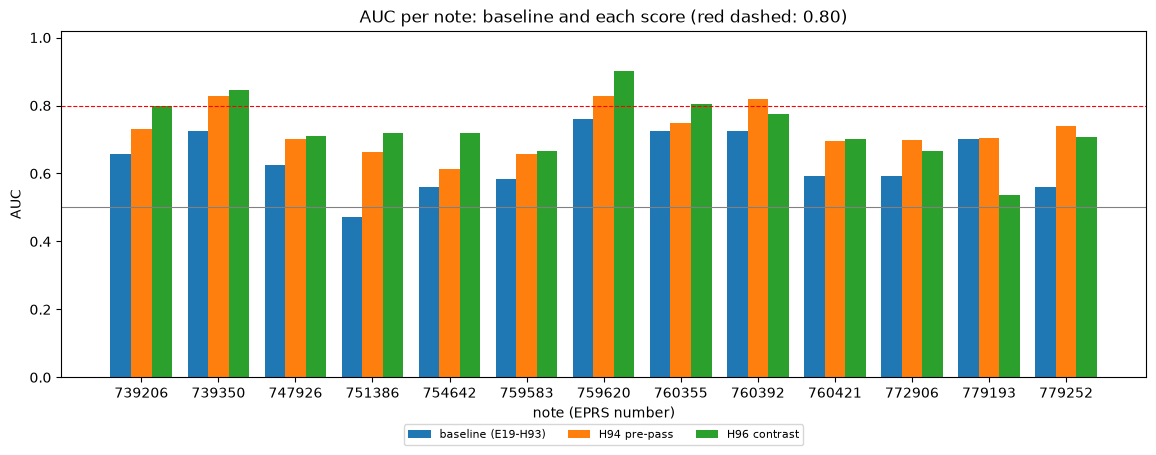

In [14]:
table = Table(title="Per-note AUC of the baseline and difference of each score (red: the score loses); hard-negative AUC of the baseline")
for col in ("note", "pos/neg", "baseline", "H94 diff", "H96 diff", "baseline hard", "H94 hard diff", "H96 hard diff", "best target rank b/H94/H96"):
    table.add_column(col, justify="left" if col == "note" else "right")
PER_BRIEF = []
for n in NOTE_IDS:
    base = AUC["baseline"][n]
    table.add_row(n, f"{LAB[n]['pos'].sum()}/{LAB[n]['neg'].sum()}", f"{base:.4f}", cell(AUC["H94"][n] - base), cell(AUC["H96"][n] - base),
                  f"{AUC_HARD['baseline'][n]:.4f}", cell(AUC_HARD["H94"][n] - AUC_HARD["baseline"][n]), cell(AUC_HARD["H96"][n] - AUC_HARD["baseline"][n]),
                  "/".join(str(READING[s][n]["best_target_rank"]) for s in SCORES))
    PER_BRIEF.append({"note": n, "targets": LAB[n]["targets"], "related": LAB[n]["related"], "positives": int(LAB[n]["pos"].sum()), "negatives": int(LAB[n]["neg"].sum()),
                      "neutral": int(LAB[n]["neutral"].sum()), "hard_negatives": HARD_NEG_COUNT[n],
                      "auc": {s: AUC[s][n] for s in SCORES}, "auc_hard": {s: AUC_HARD[s][n] for s in SCORES},
                      "best_target_rank": {s: READING[s][n]["best_target_rank"] for s in SCORES}, "top3_hit": {s: READING[s][n]["hit"] for s in SCORES},
                      "fixed_ba": BA[n]["fixed_ba"], "otsu_ba": BA[n]["otsu_ba"]})
console.print(table)
for s in ("H94", "H96"):
    losers = [n[:6] for n in NOTE_IDS if AUC[s][n] - AUC["baseline"][n] <= 0]
    console.print(f"{s}: notes with a difference at or below 0: {losers if losers else 'none'}")

fig, ax = plt.subplots(figsize=(14, 4.5))
width = 0.8 / len(SCORES)
labels = {"baseline": "baseline (E19-H93)", "H94": "H94 pre-pass", "H96": "H96 contrast"}
for k, s in enumerate(SCORES):
    ax.bar(np.arange(13) + k * width, [AUC[s][n] for n in NOTE_IDS], width, label=labels[s])
ax.set_xticks(np.arange(13) + 0.4 - width / 2, [n.split("-")[0] for n in NOTE_IDS], rotation=0)
ax.set_xlabel("note (EPRS number)"); ax.set_ylabel("AUC"); ax.set_ylim(0.0, 1.02); ax.axhline(0.5, color="grey", lw=0.8)
ax.axhline(H93_BAR_AUC, color="red", ls="--", lw=0.8)
ax.set_title("AUC per note: baseline and each score (red dashed: 0.80)"); ax.legend(ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.12), fontsize=8)
plt.show()

## Metrics file

In [15]:
metrics = {
    "batch": "E19", "notebook": "B",
    "written_utc": datetime.now(timezone.utc).isoformat(timespec="seconds"),
    "environment": {"docdistance": docdistance.__version__, "python": platform.python_version(), "numpy": np.__version__, "POT": ot.__version__,
                    "encoder_backend": dd.backend, "reader": "default (auto by extension)", "DIFF_CHANGED_COST": DIFF_CHANGED_COST},
    "fixture_sha256": fixture_sha, "fixture_sha256_equals_registration": HASH_EQUAL, "label_assertion_passed": LABEL_ASSERTION_PASSED,
    "statement_counts": {"report": N_REPORT, "notes": {n: len(NOTE_TEXTS[n]) for n in ALL_NOTE_IDS}, "units_total": len(SECTION_ROWS), "units_with_statements": len(UNITS), "units_ranked": len(RANKED_UNITS)},
    "label_counts": {n: {"positives": int(l["pos"].sum()), "negatives": int(l["neg"].sum()), "neutral": int(l["neutral"].sum())} for n, l in LAB.items()},
    "auc_per_note": {n: {s: AUC[s][n] for s in SCORES} for n in NOTE_IDS},
    "auc_hard_negatives_per_note": {n: {s: AUC_HARD[s][n] for s in SCORES} for n in NOTE_IDS},
    "summary": SUMMARY,
    "section_reading": READING, "top3_hits": HITS,
    "balanced_accuracy_per_note": BA, "balanced_accuracy_means": {"fixed": FIXED_MEAN, "otsu": OTSU_MEAN},
    "note_without_target": NOTE0,
    "gates": {"baseline_auc": {"value": BASE_MEAN, "threshold": BATCH_GATE_AUC, "killed": GATE_AUC_KILLED},
              "fixed_cutoff_ba": {"value": FIXED_MEAN, "threshold": H97_GATE_BA, "killed": GATE_BA_KILLED}},
    "decisions": DECISION,
    "verdict_by_bar": {h: DECISION[h]["verdict_by_bar"] for h in ("E19-H93", "E19-H94", "E19-H96", "E19-H97")},
    "wall_seconds": round(time.time() - T_START, 1),
}
METRICS_FILE.write_text(json.dumps(metrics, indent=1, default=float), encoding="utf-8")
console.print(f"written {METRICS_FILE.relative_to(ROOT)} ({METRICS_FILE.stat().st_size} bytes)")
console.print(metrics["verdict_by_bar"])

written reports/E19-real-document-map-metrics.json (32044 bytes)

{'E19-H93': 'Refuted', 'E19-H94': 'Confirmed', 'E19-H96': 'Confirmed', 'E19-H97': 'Refuted'}

## Conclusions

**Gates.** The baseline mean AUC over the 13 notes is 0.6374 against the gate of 0.95, so `E19-H94` and `E19-H96` go on to their bars. The fixed-cutoff mean balanced accuracy is 0.5835 against the gate of 0.65, so `E19-H97` goes on to its bar.

**E19-H93 - Refuted by the bar.** The baseline mean AUC is 0.6374 (bar 0.80) and no note reaches an AUC of 0.80 (best 0.7614). The target section is among the 3 best-ranked units for 5 of 13 notes (bar 10). Both clauses fail. With hard negatives (negatives of the target's own chapter) the mean AUC is 0.6305, so the weak ranking does not come from easy-to-confuse sections of other chapters only. The 3 best-ranked units of the baseline are often the same units for different notes (for example 5.2, 5.4, 4.3 and 4.2), which the baseline ranks high regardless of the note. This is consistent with the mechanism that statements near every text matter, but the notebook does not test that cause.

**E19-H94 - Confirmed by the bar.** The pre-pass raises the mean AUC from 0.6374 to 0.7250, a mean difference of +0.0876 (bar 0.03), with a difference above 0 in 13 of 13 notes (bar 10). The bootstrap interval of the mean difference over the 13 notes is [+0.0603, +0.1170]. The top-3 hit count rises from 5 to 12 of 13 (reported, no bar). The mean AUC of 0.7250 is still below 0.80, so the pre-pass improves the ranking without making it reliable at the level of single statements.

**E19-H96 - Confirmed by the bar.** The contrast raises the mean AUC from 0.6374 to 0.7345, a mean difference of +0.0971 (bar 0.03), with a difference above 0 in 12 of 13 notes (bar 10). The bootstrap interval is [+0.0427, +0.1405]. The one losing note is 779193 (AUC difference -0.1655; its best target unit falls from rank 1 to rank 9). The top-3 hit count is 12 of 13. The contrast and the pre-pass differ by 0.0095 in mean AUC, which is small against the bootstrap intervals; the notebook makes no claim about which of the two is better.

**E19-H97 - Refuted by the bar.** The Otsu split of the contrast reads a mean balanced accuracy of 0.6592 (bar 0.70) and is +0.0756 above the fixed cutoff's 0.5835 (bar +0.10). Both clauses fail. The split improves 12 of 13 notes over the fixed cutoff but marks about 40 percent of the report statements as matches (mean 0.4026 share), against 6 percent for the fixed cutoff; the true-negative rate falls to 0.45 to 0.72 for most notes. The fixed cutoff marks very few statements as matches (true-positive rate 0.04 to 0.40).

**Note without a target section (reported, no bar, not part of any mean).** For the note on the enforcement of data protection, the fixed cutoff marks 2.27 percent of the report statements and the Otsu split of its contrast marks 47.45 percent. The split therefore marks a large share of the report as matching a note that has no target section, so a split of the contrast alone does not identify a note without a matching section. The 3 best-ranked units are 5.2, 3.1 and 5.4 for the baseline and 5.2, 3.2.1 and 5.1 for the pre-pass; the contrast ranks 3.2.2, 3.3.1 and 3.1.

**Section reading.** The mean best rank of a target unit among 33 to 36 ranked units is 7.62 for the baseline, 1.62 for the pre-pass and 2.31 for the contrast.

**What the fixture cannot show.** One report and 13 notes from two EU institutions, in English; one annotator assigned the labels at section level, so a statement outside a target section that is relevant to a note counts as a negative, and a section-level label is coarser than a statement-level relevance; the notes were written about legislative files and not for this report; four notes share or overlap subjects (two notes share the target section 3.2.3, two notes read the AI sections), so the 13 notes are not independent; 13 notes give wide bootstrap intervals; the 8 units that hold fewer than 5 statements are left out (1, 2, 2.1.3, 2.2, 2.2.1, 3.2, 3.3 and 5); the unit score uses the statements that belong to the deepest unit of their path, so the statements of a recommendation box count for the numbered section above it (3.1.1 holds 9 statements this way and is ranked); 113 of the 883 scored statements are heading lines of the report, which count as positive or negative by their section path and inside the 5-statement threshold of a unit; the version string 1.1.32 does not identify the code of this run, because `src/docdistance/pipeline.py` and `src/docdistance/cli.py` carried uncommitted changes of a separate build (new fields of the map file) while the notebook ran - the readings use `embed_statements`, `cost_matrix`, `all_but_the_top` and the `section` field of the map.